# Imports & Setup


In [1]:
import json
import random
import time
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix

artifact_root = Path(r'D:\EEG Experiment Artifacts\2026-11-02')
dataset_root = Path(r'C:\FACED dataset')

import pickle
import warnings
import joblib
from scipy.io import loadmat
from scipy.stats import sem
from sklearn.svm import LinearSVC
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits


# Config


In [2]:
num_classes = 9

run_dir = artifact_root / 'runs/faced_svm_5band_reference'
run_training = False
seed = 7
n_jobs = 4
C_candidates = 10.0 ** np.arange(-5, 1, 0.5)
config = json.loads((run_dir / 'config.json').read_text())
print('Classes:', num_classes)
print('Features: 30 channels x 5 DE bands, one-second windows')
print('123 subjects, ten folds: 12 subjects in folds 0-8 and 15 in fold 9')
print('Saved run: 2026-11-02. Training is disabled while loading its results.')
print('C is selected on the reporting fold, matching the reference protocol; scores are optimistic.')
print('Adaptations: five bands, corrected last-fold statistics, primal LinearSVC.')


Classes: 9
Features: 30 channels x 5 DE bands, one-second windows
123 subjects, ten folds: 12 subjects in folds 0-8 and 15 in fold 9
Saved run: 2026-11-02. Training is disabled while loading its results.
C is selected on the reporting fold, matching the reference protocol; scores are optimistic.
Adaptations: five bands, corrected last-fold statistics, primal LinearSVC.


# Load & Preprocess & Split Data


In [3]:
selected = np.r_[0:12, 16:28] if num_classes == 2 else np.arange(28)
video_labels = (np.r_[np.zeros(12, dtype=int), np.ones(12, dtype=int)]
                if num_classes == 2 else np.repeat(np.arange(9), [3,3,3,3,4,3,3,3,3]))
labels = np.tile(np.repeat(video_labels, 30), (123, 1))
print('Labels:', labels.shape, '- fixed stimulus categories')

if run_training:
    feature_dir = dataset_root / 'EEG_Features/DE'
    de = np.stack([pickle.load(open(feature_dir / f'sub{s:03d}.pkl.pkl', 'rb'))[:, :30]
                   for s in range(123)])
    de = de.transpose(0, 1, 3, 4, 2).reshape(123, 28, 30, 150)
    data = de[:, selected].reshape(123, len(selected) * 30, 150)
    orders = []
    for s in range(123):
        remark = loadmat(dataset_root / 'Data' / f'sub{s:03d}' / 'After_remarks.mat')['After_remark']
        order = [int(v.item()) - 1 for v in remark['vid'].ravel()]
        orders.append([np.flatnonzero(selected == v)[0] for v in order if v in selected])
    orders = np.array(orders)
else:
    saved_predictions = np.load(run_dir / f'predictions_{num_classes}class.npz')
    assert np.array_equal(labels, saved_predictions['labels'])
    print('Using saved predictions and model weights.')


Labels: (123, 840) - fixed stimulus categories
Using saved predictions and model weights.


# DE + SVM Model


In [4]:
def normalize_lds(data, orders, train):
    n, t, d = data.shape
    vids = t // 30
    chronological = np.stack([data[s].reshape(vids, 30, d)[orders[s]].reshape(t, d) for s in range(n)])
    chronological[~np.isfinite(chronological)] = -30
    mean = chronological[train].mean(axis=1).mean(axis=0)
    var = chronological[train].var(axis=1).mean(axis=0)
    count = np.arange(1, t + 1)[None, :, None]
    sums = np.cumsum(chronological, axis=1)
    running_mean = sums / count
    running_var = (np.cumsum(chronological ** 2, axis=1) - 2 * running_mean * sums) / count + running_mean ** 2
    decay = (0.99 ** np.arange(t))[None, :, None]
    norm = (chronological - (decay * mean + (1 - decay) * running_mean)) / np.sqrt(decay * var + (1 - decay) * running_var + 1e-05)
    canonical = np.empty((n, vids, 30, d))
    for s in range(n):
        canonical[s, orders[s]] = norm[s].reshape(vids, 30, d)
    canonical = canonical.reshape(n, t, d)
    smooth = np.empty_like(canonical)
    v = 0.01 / (1 + 0.01)
    smooth[:, 0] = canonical.mean(axis=1) + v * (canonical[:, 0] - canonical.mean(axis=1))
    variance = (1 - v) * 0.01
    for second in range(1, t):
        prior = variance + 0.0001
        gain = prior / (prior + 1)
        smooth[:, second] = smooth[:, second - 1] + gain * (canonical[:, second] - smooth[:, second - 1])
        variance = (1 - gain) * prior
    std = smooth.std(axis=1, keepdims=True)
    std[std == 0] = 1
    return (smooth - smooth.mean(axis=1, keepdims=True)) / std

def fit_candidate(c, xtrain, ytrain, xtest, ytest):
    t0 = time.perf_counter()
    clf = LinearSVC(C=c, random_state=7, dual=False, max_iter=1000, tol=0.0001)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', ConvergenceWarning)
        with threadpool_limits(limits=1):
            clf.fit(xtrain, ytrain)
    acc = float(np.mean(clf.predict(xtest) == ytest))
    return (clf, {'C': c, 'accuracy': acc, 'seconds': time.perf_counter() - t0, 'n_iter': int(np.max(clf.n_iter_)), 'warnings': [str(w.message) for w in caught]})

if not run_training:
    model = joblib.load(run_dir / f'svm_{num_classes}class_fold0.joblib')
    print(model)
    print('Input features:', model.n_features_in_)


LinearSVC(C=1e-05, dual=False, random_state=7)
Input features: 150


# Training and Evaluation


In [5]:
if run_training:
    run_dir = artifact_root / 'runs' / (f'svm_{num_classes}class_' + datetime.now().strftime('%Y%m%d_%H%M%S'))
    run_dir.mkdir(parents=True, exist_ok=False)
    (run_dir / 'config.json').write_text(json.dumps(config, indent=2), encoding='utf-8')
    predictions = np.full_like(labels, -1)
    fold_rows, grid_rows = [], []

    for fold in range(10):
        start = time.perf_counter()
        held = np.arange(fold * 12, (fold + 1) * 12 if fold < 9 else 123)
        train = np.setdiff1d(np.arange(123), held)
        z = normalize_lds(data, orders, train)
        x_train, y_train = z[train].reshape(-1, 150), labels[train].ravel()
        x_test, y_test = z[held].reshape(-1, 150), labels[held].ravel()
        candidates = joblib.Parallel(n_jobs=n_jobs, prefer='processes')(
            joblib.delayed(fit_candidate)(c, x_train, y_train, x_test, y_test) for c in C_candidates)
        model, best = max(candidates, key=lambda item: item[1]['accuracy'])
        predictions[held] = model.predict(x_test).reshape(len(held), -1)
        joblib.dump(model, run_dir / f'svm_{num_classes}class_fold{fold}.joblib')
        fold_rows.append({'classes': num_classes, 'fold': fold, 'subjects': held.tolist(),
                          'best_C': best['C'], 'accuracy': best['accuracy'],
                          'seconds': time.perf_counter() - start})
        grid_rows.extend({'classes': num_classes, 'fold': fold, **trial} for _, trial in candidates)
        print(f"Fold {fold}: {best['accuracy']:.4f}, C={best['C']}")

    scores = (predictions == labels).mean(axis=1)
    np.savez(run_dir / f'predictions_{num_classes}class.npz', predictions=predictions,
             labels=labels, subject_accuracy=scores)
    (run_dir / f'folds_{num_classes}class.json').write_text(json.dumps(fold_rows, indent=2))
    (run_dir / f'grid_{num_classes}class.json').write_text(json.dumps(grid_rows, indent=2))
else:
    print('Loaded saved fold results; no SVM fits were repeated.')

folds = pd.read_json(run_dir / f'folds_{num_classes}class.json')
print(folds[['fold', 'best_C', 'accuracy', 'seconds']].to_string(index=False))


Loaded saved fold results; no SVM fits were repeated.
 fold   best_C  accuracy    seconds
    0 0.000010  0.410516 104.460142
    1 0.000010  0.415179 104.658520
    2 0.000032  0.439187 102.551981
    3 0.000010  0.441369 103.953512
    4 0.000100  0.429960 101.877056
    5 0.000100  0.357540 101.836043
    6 1.000000  0.351786  98.512282
    7 0.000100  0.371032  98.967013
    8 0.000010  0.365873  92.655957
    9 0.000100  0.366032  96.006514


# Test Results


In [6]:
saved_predictions = np.load(run_dir / f'predictions_{num_classes}class.npz')
predictions = saved_predictions['predictions']
assert predictions.shape == labels.shape and (predictions >= 0).all()
subject_scores = (predictions == labels).mean(axis=1)
metrics = {
    'Accuracy': accuracy_score(labels.ravel(), predictions.ravel()),
    'SEM across subjects': sem(subject_scores),
    'Balanced accuracy': balanced_accuracy_score(labels.ravel(), predictions.ravel()),
    'Macro F1': f1_score(labels.ravel(), predictions.ravel(), average='macro')
}
print(pd.Series(metrics).mul(100).round(2).to_string())
print('Subjects:', len(subject_scores), '- folds:', len(folds))
print('Adapted reference execution; differences from the original release are recorded in Config.')


Accuracy               39.41
SEM across subjects     1.08
Balanced accuracy      38.54
Macro F1               37.97
Subjects: 123 - folds: 10
Adapted reference execution; differences from the original release are recorded in Config.


# Plot Results


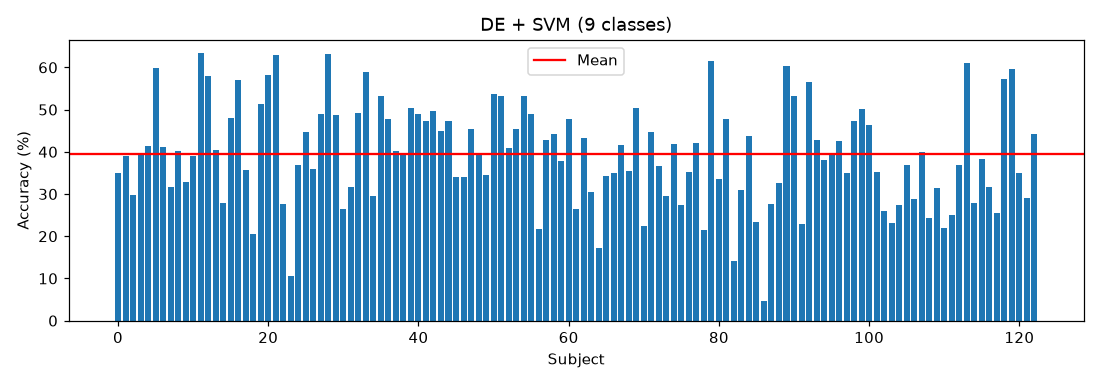

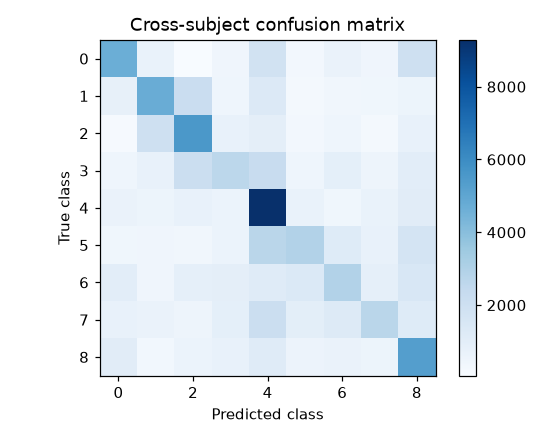

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(np.arange(123), subject_scores * 100)
ax.axhline(subject_scores.mean() * 100, color='red', label='Mean')
ax.set(xlabel='Subject', ylabel='Accuracy (%)', title=f'DE + SVM ({num_classes} classes)')
ax.legend()
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(confusion_matrix(labels.ravel(), predictions.ravel()), cmap='Blues')
ax.set(xlabel='Predicted class', ylabel='True class', title='Cross-subject confusion matrix')
fig.colorbar(image, ax=ax)
fig.tight_layout()
plt.show()
